# Crop Yield Prediction Project

## 1. Data Cleaning and Integration



In [ ]:
import pandas as pd

print("--- Step 1: Loading and Cleaning District-Level Annual Data ---")
annual_district_file = '32_13AnnualAverageRainFall (3).csv'

# Load the data
df_punjab_annual = pd.read_csv(annual_district_file)

# Rename the first column to 'District'
df_punjab_annual.rename(columns={'District/Year': 'District'}, inplace=True)

# Reshape from wide to long format to make it usable
df_punjab_long = pd.melt(df_punjab_annual,
                         id_vars=['District'],
                         var_name='Year',
                         value_name='Annual_Rainfall_District_mm')

# Clean up the data types, converting any non-numeric values to NaN (Not a Number)
df_punjab_long['Year'] = pd.to_numeric(df_punjab_long['Year'], errors='coerce')
df_punjab_long['Annual_Rainfall_District_mm'] = pd.to_numeric(df_punjab_long['Annual_Rainfall_District_mm'], errors='coerce')

# Drop any rows that have missing data after our conversion
df_punjab_long.dropna(inplace=True)

# Make sure the 'Year' column is a clean integer (e.g., 2018 not 2018.0)
df_punjab_long['Year'] = df_punjab_long['Year'].astype(int)

print("District-level data cleaned successfully.")
print(df_punjab_long.head())

print("\n--- Step 2: Engineering Seasonal Features from State-Level Monthly Data ---")
monthly_state_file = 'Rainfall_Data_LL.csv'

# Load the monthly data
df_monthly = pd.read_csv(monthly_state_file)

# Filter to get only the data for the 'Punjab' subdivision
df_punjab_monthly = df_monthly[df_monthly['SUBDIVISION'] == 'Punjab'].copy()

# Rename 'YEAR' to 'Year' to match our other file for merging
df_punjab_monthly.rename(columns={'YEAR': 'Year'}, inplace=True)

# Create powerful seasonal features by summing the relevant months
# Kharif season (e.g., for Rice) is dominated by the monsoon
df_punjab_monthly['Kharif_Rainfall_State_mm'] = df_punjab_monthly['JUN'] + df_punjab_monthly['JUL'] + df_punjab_monthly['AUG'] + df_punjab_monthly['SEP']
# Rabi season (e.g., for Wheat) uses winter and spring rain
df_punjab_monthly['Rabi_Rainfall_State_mm'] = df_punjab_monthly['OCT'] + df_punjab_monthly['NOV'] + df_punjab_monthly['DEC'] + df_punjab_monthly['JAN'] + df_punjab_monthly['FEB'] + df_punjab_monthly['MAR']

# Select only the columns we need for our final dataset
df_seasonal_state = df_punjab_monthly[['Year', 'Kharif_Rainfall_State_mm', 'Rabi_Rainfall_State_mm']]

print("Seasonal features engineered successfully.")
print(df_seasonal_state.head())

print("\n--- Step 3: Merging the Datasets and Handling Final Missing Values ---")
# Merge the two dataframes using 'Year' as the common key
# A 'left' merge ensures we keep all district-level data
df_merged = pd.merge(df_punjab_long, df_seasonal_state, on='Year', how='left')

# Check for any missing values after the merge
print(f"Missing values found after merging:\n{df_merged.isnull().sum()}")

# Impute any missing values with the median of the column
for col in ['Annual_Rainfall_District_mm', 'Kharif_Rainfall_State_mm', 'Rabi_Rainfall_State_mm']:
    if df_merged[col].isnull().any():
        median_value = df_merged[col].median()
        df_merged[col].fillna(median_value, inplace=True)

print("\nMissing values after imputation:\n", df_merged.isnull().sum())

# Sort the final dataframe for readability
df_merged.sort_values(by=['District', 'Year'], inplace=True)

print("\n--- Step 4: Saving the Final Merged File ---")
output_path = 'merged_rainfall_data.csv'
df_merged.to_csv(output_path, index=False)

print(f"Success! The final merged and cleaned data has been saved to '{output_path}'")
print("\nFinal Data Preview:")
print(df_merged.head())

--- Step 1: Loading and Cleaning District-Level Annual Data ---
District-level data cleaned successfully.
     District  Year  Annual_Rainfall_District_mm
0   Gurdaspur  2021                        714.8
2    Amritsar  2021                        518.4
3  Tarn Taran  2021                        401.6
4  Kapurthala  2021                       1108.3
5   Jalandhar  2021                        828.3

--- Step 2: Engineering Seasonal Features from State-Level Monthly Data ---
Seasonal features engineered successfully.
      Year  Kharif_Rainfall_State_mm  Rabi_Rainfall_State_mm
1498  1901                     358.0                   138.0
1499  1902                     337.6                    19.8
1500  1903                     469.0                    91.4
1501  1904                     279.7                   156.8
1502  1905                     303.2                   128.2

--- Step 3: Merging the Datasets and Handling Final Missing Values ---
Missing values found after merging:
Distri

/tmp/ipython-input-2183456584.py:68: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_merged[col].fillna(median_value, inplace=True)


In [ ]:
import pandas as pd
import numpy as np

# --- Step 1: Load the Foundational Dataset ---
file_path = 'crop_production.csv'
print(f"Loading '{file_path}'...")
try:
    df = pd.read_csv(file_path)
    print("File loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: Make sure '{file_path}' is in the same directory as your script.")
    exit()

# --- Step 2: Filter for Punjab ---
print("\nFiltering data to keep only records for Punjab...")
df_punjab = df[df['State_Name'] == 'Punjab'].copy()
print(f"Found {len(df_punjab)} records for Punjab.")

# --- Step 3: Clean and Standardize Data ---
print("\nCleaning column names and standardizing text...")
df_punjab.rename(columns={
    'District_Name': 'District',
    'Crop_Year': 'Year',
    'Area': 'Area_Hectares',
    'Production': 'Production_Tonnes'
}, inplace=True)
df_punjab['Season'] = df_punjab['Season'].str.strip()
df_punjab['Crop'] = df_punjab['Crop'].str.strip()
df_punjab['Area_Hectares'] = pd.to_numeric(df_punjab['Area_Hectares'], errors='coerce')
df_punjab['Production_Tonnes'] = pd.to_numeric(df_punjab['Production_Tonnes'], errors='coerce')
df_punjab.dropna(subset=['Area_Hectares', 'Production_Tonnes'], inplace=True)
print("Data cleaned.")

# --- Step 4: Calculate the Target Variable (Yield) ---
print("\nCalculating Yield (Tonnes per Hectare)...")
df_punjab['Area_Hectares'] = df_punjab['Area_Hectares'].replace(0, np.nan)
df_punjab['Yield_Tonnes_Per_Hectare'] = df_punjab['Production_Tonnes'] / df_punjab['Area_Hectares']
df_punjab.dropna(subset=['Yield_Tonnes_Per_Hectare'], inplace=True)
print("Yield calculated successfully.")

# --- Step 5: Finalize and Save ---
final_columns = [
    'State_Name', 'District', 'Year', 'Season', 'Crop',
    'Area_Hectares', 'Production_Tonnes', 'Yield_Tonnes_Per_Hectare'
]
df_cleaned_agronomic = df_punjab[final_columns]
df_cleaned_agronomic.sort_values(by=['District', 'Year', 'Crop'], inplace=True)
output_path = 'cleaned_agronomic_data.csv'
df_cleaned_agronomic.to_csv(output_path, index=False)

print("\n--------------------------------------------------")
print(f"✅ Success! Your foundational data is clean and ready.")
print(f"A new file has been saved: '{output_path}'")
print("\nHere is a preview of your clean data:")
print(df_cleaned_agronomic.head())
print("--------------------------------------------------")

Loading 'crop_production.csv'...
File loaded successfully.

Filtering data to keep only records for Punjab...
Found 3173 records for Punjab.

Cleaning column names and standardizing text...
Data cleaned.

Calculating Yield (Tonnes per Hectare)...
Yield calculated successfully.

--------------------------------------------------
✅ Success! Your foundational data is clean and ready.
A new file has been saved: 'cleaned_agronomic_data.csv'

Here is a preview of your clean data:
       State_Name  District  Year      Season          Crop  Area_Hectares  \
161267     Punjab  AMRITSAR  1997      Kharif     Arhar/Tur         1800.0   
161268     Punjab  AMRITSAR  1997      Kharif         Bajra         1000.0   
161277     Punjab  AMRITSAR  1997  Whole Year  Cotton(lint)         5000.0   
161273     Punjab  AMRITSAR  1997        Rabi          Gram          400.0   
161269     Punjab  AMRITSAR  1997      Kharif         Maize         7000.0   

        Production_Tonnes  Yield_Tonnes_Per_Hectare 

In [ ]:
import pandas as pd

# --- Step 1: Load Our Clean Datasets ---
agronomic_file = 'cleaned_agronomic_data.csv'
rainfall_file = 'merged_rainfall_data.csv'

print(f"Loading '{agronomic_file}' and '{rainfall_file}'...")
try:
    df_agronomic = pd.read_csv(agronomic_file)
    df_rainfall = pd.read_csv(rainfall_file)
    print("Files loaded successfully.")
except FileNotFoundError as e:
    print(f"ERROR: File not found. Please make sure '{e.filename}' is in the same directory.")
    exit()

# --- Step 2: Perform the Left Merge ---
print("\nMerging the rainfall data into the agronomic data...")
# We merge on 'District' and 'Year'.
# A 'left' merge keeps everything from the left dataframe (df_agronomic).
df_merged = pd.merge(df_agronomic, df_rainfall,
                     on=['District', 'Year'],
                     how='left')

print("Merge complete.")

# --- Step 3: Handle Potential Missing Values Post-Merge ---
# If a rainfall value was not found for a specific district/year, it will be 'NaN'.
# We can fill these gaps with the median of the column.
rainfall_cols = ['Annual_Rainfall_District_mm', 'Kharif_Rainfall_State_mm', 'Rabi_Rainfall_State_mm']
for col in rainfall_cols:
    if df_merged[col].isnull().any():
        print(f"Missing values found in '{col}'. Imputing with median...")
        median_value = df_merged[col].median()
        df_merged[col].fillna(median_value, inplace=True)
        print("Missing values filled.")
else:
    print("\nNo missing rainfall values found after the merge. Excellent!")


# --- Step 4: Save the New Merged File ---
output_path = 'agronomic_plus_rainfall_data.csv'
df_merged.to_csv(output_path, index=False)

print("\n--------------------------------------------------")
print(f"✅ Success! Your rainfall data has been integrated.")
print(f"A new file has been saved: '{output_path}'")
print("\nHere is a preview of your newly merged data (scroll right to see new columns):")
print(df_merged.head())
print("--------------------------------------------------")

Loading 'cleaned_agronomic_data.csv' and 'merged_rainfall_data.csv'...
Files loaded successfully.

Merging the rainfall data into the agronomic data...
Merge complete.
Missing values found in 'Annual_Rainfall_District_mm'. Imputing with median...
Missing values filled.
Missing values found in 'Kharif_Rainfall_State_mm'. Imputing with median...
Missing values filled.
Missing values found in 'Rabi_Rainfall_State_mm'. Imputing with median...
Missing values filled.

No missing rainfall values found after the merge. Excellent!

--------------------------------------------------
✅ Success! Your rainfall data has been integrated.
A new file has been saved: 'agronomic_plus_rainfall_data.csv'

Here is a preview of your newly merged data (scroll right to see new columns):
  State_Name  District  Year      Season          Crop  Area_Hectares  \
0     Punjab  AMRITSAR  1997      Kharif     Arhar/Tur         1800.0   
1     Punjab  AMRITSAR  1997      Kharif         Bajra         1000.0   
2     Pu

/tmp/ipython-input-2188970378.py:34: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_merged[col].fillna(median_value, inplace=True)


In [ ]:
import pandas as pd

# --- Step 1: Load the two files we are trying to merge ---
agronomic_file = 'cleaned_agronomic_data.csv'
rainfall_file = 'merged_rainfall_data.csv'

print(f"Loading '{agronomic_file}' and '{rainfall_file}' for inspection...")
try:
    df_agronomic = pd.read_csv(agronomic_file)
    df_rainfall = pd.read_csv(rainfall_file)
    print("Files loaded successfully.")
except FileNotFoundError as e:
    print(f"ERROR: File not found. Please make sure '{e.filename}' is in the same directory.")
    exit()

print("\n" + "="*70 + "\n")

# --- Step 2: Check the Data Types of the Key Columns ---
print("🕵️  Inspecting Data Types...")
print("\nData types for Agronomic file:")
print(df_agronomic[['District', 'Year']].dtypes)

print("\nData types for Rainfall file:")
print(df_rainfall[['District', 'Year']].dtypes)
print("\n   >> ANALYSIS: The data types for 'District' should both be 'object' (text).")
print("   >> The data types for 'Year' should both be 'int64' (number). If they differ, this is a problem.")

print("\n" + "="*70 + "\n")


# --- Step 3: Check the Unique District Names ---
print("🕵️  Inspecting Unique District Names...")
# Get the unique district names from each file
agronomic_districts = sorted(df_agronomic['District'].unique())
rainfall_districts = sorted(df_rainfall['District'].unique())

print(f"\nFound {len(agronomic_districts)} unique districts in the Agronomic file.")
print(f"Found {len(rainfall_districts)} unique districts in the Rainfall file.")

# Find districts that are in one file but not the other
# This is a powerful way to find spelling or formatting differences.
agronomic_only = set(agronomic_districts) - set(rainfall_districts)
rainfall_only = set(rainfall_districts) - set(agronomic_districts)

print("\n   >> ANALYSIS: If the district names are perfectly matched, the next two lists should be empty.")
print(f"\nDistricts found ONLY in the Agronomic file: {list(agronomic_only)}")
print(f"Districts found ONLY in the Rainfall file: {list(rainfall_only)}")


print("\n" + "="*70 + "\n")


# --- Step 4: Check the Range of Years ---
print("🕵️  Inspecting the Range of Years...")
print(f"\nAgronomic data covers years: {df_agronomic['Year'].min()} to {df_agronomic['Year'].max()}")
print(f"Rainfall data covers years: {df_rainfall['Year'].min()} to {df_rainfall['Year'].max()}")
print("\n   >> ANALYSIS: The years in both files must have a good amount of overlap for a successful merge.")

print("\n" + "="*70 + "\n")

Loading 'cleaned_agronomic_data.csv' and 'merged_rainfall_data.csv' for inspection...
Files loaded successfully.


🕵️  Inspecting Data Types...

Data types for Agronomic file:
District    object
Year         int64
dtype: object

Data types for Rainfall file:
District    object
Year         int64
dtype: object

   >> ANALYSIS: The data types for 'District' should both be 'object' (text).
   >> The data types for 'Year' should both be 'int64' (number). If they differ, this is a problem.


🕵️  Inspecting Unique District Names...

Found 22 unique districts in the Agronomic file.
Found 21 unique districts in the Rainfall file.

   >> ANALYSIS: If the district names are perfectly matched, the next two lists should be empty.

Districts found ONLY in the Agronomic file: ['FARIDKOT', 'TARN TARAN', 'S.A.S NAGAR', 'PATIALA', 'NAWANSHAHR', 'JALANDHAR', 'FATEHGARH SAHIB', 'BATHINDA', 'LUDHIANA', 'FIROZEPUR', 'FAZILKA', 'MANSA', 'PATHANKOT', 'AMRITSAR', 'HOSHIARPUR', 'KAPURTHALA', 'RUPNAGAR', 'BARNA

In [ ]:
import pandas as pd

# --- Step 1: Load the two files ---
agronomic_file = 'cleaned_agronomic_data.csv'
rainfall_file = 'merged_rainfall_data.csv'

print(f"Loading '{agronomic_file}' and '{rainfall_file}'...")
try:
    df_agronomic = pd.read_csv(agronomic_file)
    df_rainfall = pd.read_csv(rainfall_file)
    print("Files loaded successfully.")
except FileNotFoundError as e:
    print(f"ERROR: File not found. Please make sure '{e.filename}' is in the same directory.")
    exit()

# --- Step 2: FIX THE DISTRICT NAMES ---
print("\nStandardizing district names...")

# Fix 1: Convert 'District' column to uppercase in both dataframes
df_agronomic['District'] = df_agronomic['District'].str.upper().str.strip()
df_rainfall['District'] = df_rainfall['District'].str.upper().str.strip()

# Fix 2: Create a mapping for inconsistent names
name_map = {
    'SBS NAGAR': 'NAWANSHAHR',
    'SRI MUKTSAR SAHIB': 'MUKTSAR',
    'SAS NAGAR': 'S.A.S NAGAR'
}
# Apply the mapping to the rainfall dataframe
df_rainfall['District'] = df_rainfall['District'].replace(name_map)

# Fix 3: Remove the row where the district is 'PUNJAB' (the state)
df_rainfall = df_rainfall[df_rainfall['District'] != 'PUNJAB']

print("District names have been standardized.")

# (Optional) Verify the fix
print("\nVerifying the fix...")
agronomic_districts = sorted(df_agronomic['District'].unique())
rainfall_districts = sorted(df_rainfall['District'].unique())
if set(agronomic_districts) == set(rainfall_districts):
    print("✅ Success! District names now match perfectly.")
else:
    print("⚠️ Warning: Some districts still do not match.")


# --- Step 3: Perform the Corrected Merge ---
print("\nPerforming the corrected merge...")
df_merged = pd.merge(df_agronomic, df_rainfall,
                     on=['District', 'Year'],
                     how='left')
print("Merge complete.")

# --- Step 4: Impute and Save ---
# Impute any missing values that might still exist
rainfall_cols = ['Annual_Rainfall_District_mm', 'Kharif_Rainfall_State_mm', 'Rabi_Rainfall_State_mm']
for col in rainfall_cols:
    if df_merged[col].isnull().any():
        median_value = df_merged[col].median()
        df_merged[col].fillna(median_value, inplace=True)

# Save the final, correctly merged file
output_path = 'agronomic_plus_rainfall_data.csv'
df_merged.to_csv(output_path, index=False)


print("\n--------------------------------------------------")
print(f"✅ Success! The data has been correctly merged.")
print(f"The updated file has been saved: '{output_path}'")
print("\nHere is a preview of your correctly merged data:")
print(df_merged.head())
print("--------------------------------------------------")

Loading 'cleaned_agronomic_data.csv' and 'merged_rainfall_data.csv'...
Files loaded successfully.

Standardizing district names...
District names have been standardized.

Verifying the fix...
⚠️ Warning: Some districts still do not match.

Performing the corrected merge...
Merge complete.

--------------------------------------------------
✅ Success! The data has been correctly merged.
The updated file has been saved: 'agronomic_plus_rainfall_data.csv'

Here is a preview of your correctly merged data:
  State_Name  District  Year      Season          Crop  Area_Hectares  \
0     Punjab  AMRITSAR  1997      Kharif     Arhar/Tur         1800.0   
1     Punjab  AMRITSAR  1997      Kharif         Bajra         1000.0   
2     Punjab  AMRITSAR  1997  Whole Year  Cotton(lint)         5000.0   
3     Punjab  AMRITSAR  1997        Rabi          Gram          400.0   
4     Punjab  AMRITSAR  1997      Kharif         Maize         7000.0   

   Production_Tonnes  Yield_Tonnes_Per_Hectare  Annual

/tmp/ipython-input-3474763990.py:60: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_merged[col].fillna(median_value, inplace=True)


In [ ]:
import pandas as pd

def process_fertilizer_file(file_path, value_name):
    """
    A helper function to load, clean, and reshape a single fertilizer file.
    """
    try:
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f"ERROR: File not found -> {file_path}. Please ensure it's in the directory.")
        return None

    df.rename(columns={df.columns[0]: 'District'}, inplace=True)
    df_long = pd.melt(df,
                      id_vars=['District'],
                      var_name='Year',
                      value_name=value_name)
    df_long['Year'] = pd.to_numeric(df_long['Year'], errors='coerce')
    df_long.dropna(subset=['Year'], inplace=True)
    df_long['Year'] = df_long['Year'].astype(int)
    df_long[value_name] = pd.to_numeric(df_long[value_name], errors='coerce')
    df_long.dropna(subset=[value_name], inplace=True)
    df_long['District'] = df_long['District'].str.upper().str.strip()
    return df_long

# --- Step 1: Process Each Fertilizer File Individually ---
print("Processing individual fertilizer files...")

df_n = process_fertilizer_file('Table_4.24_NConsumption.csv', 'N_Consumption_Tonnes')
df_p = process_fertilizer_file('Table_4.24_P2O5_Consumption.csv', 'P_Consumption_Tonnes')
df_k = process_fertilizer_file('Table_4.24_K2O_Consumption.csv', 'K_Consumption_Tonnes')

if df_n is None or df_p is None or df_k is None:
    print("\nOne or more fertilizer files could not be processed. Exiting.")
    exit()

# --- Step 2: Combine the Three Fertilizer Datasets ---
print("\nMerging N, P, and K data into a single fertilizer table...")
df_fertilizer_master = pd.merge(df_n, df_p, on=['District', 'Year'], how='outer')
df_fertilizer_master = pd.merge(df_fertilizer_master, df_k, on=['District', 'Year'], how='outer')
print("Fertilizer data combined.")

# --- Step 3: Load Current Master Data and Perform Final Merge ---
master_file = 'agronomic_plus_rainfall_data.csv'
print(f"\nLoading current master data from '{master_file}'...")
try:
    df_master = pd.read_csv(master_file)
    print("Master data loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The master file '{master_file}' was not found.")
    exit()

# Standardize district names in master file before merging
df_master['District'] = df_master['District'].str.upper().str.strip()

print("\nMerging fertilizer data into the master data...")
df_final_merged = pd.merge(df_master, df_fertilizer_master, on=['District', 'Year'], how='left')

# --- Step 4: Handle Missing Values and Save ---
for col in ['N_Consumption_Tonnes', 'P_Consumption_Tonnes', 'K_Consumption_Tonnes']:
    if df_final_merged[col].isnull().any():
        median_value = df_final_merged[col].median()
        df_final_merged[col].fillna(median_value, inplace=True)

output_path = 'master_data_v1.csv'
df_final_merged.to_csv(output_path, index=False)


print("\n--------------------------------------------------")
print(f"✅ Success! All NPK fertilizer data has been integrated.")
print(f"A new file has been saved as: '{output_path}'")
print("\nHere is a preview of your new master data:")
print(df_final_merged.head())
print("--------------------------------------------------")

Processing individual fertilizer files...

Merging N, P, and K data into a single fertilizer table...
Fertilizer data combined.

Loading current master data from 'agronomic_plus_rainfall_data.csv'...
Master data loaded successfully.

Merging fertilizer data into the master data...


/tmp/ipython-input-1922444662.py:63: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_final_merged[col].fillna(median_value, inplace=True)



--------------------------------------------------
✅ Success! All NPK fertilizer data has been integrated.
A new file has been saved as: 'master_data_v1.csv'

Here is a preview of your new master data:
  State_Name  District  Year      Season          Crop  Area_Hectares  \
0     Punjab  AMRITSAR  1997      Kharif     Arhar/Tur         1800.0   
1     Punjab  AMRITSAR  1997      Kharif         Bajra         1000.0   
2     Punjab  AMRITSAR  1997  Whole Year  Cotton(lint)         5000.0   
3     Punjab  AMRITSAR  1997        Rabi          Gram          400.0   
4     Punjab  AMRITSAR  1997      Kharif         Maize         7000.0   

   Production_Tonnes  Yield_Tonnes_Per_Hectare  Annual_Rainfall_District_mm  \
0             1400.0                  0.777778                        813.2   
1             1000.0                  1.000000                        813.2   
2             2000.0                  0.400000                        813.2   
3              300.0                  0.75

In [ ]:
import pandas as pd

def process_feature_file(file_path, value_name):
    """
    A helper function to load, clean, and reshape a single feature file.
    """
    try:
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f"ERROR: File not found -> {file_path}.")
        return None

    df.rename(columns={df.columns[0]: 'District'}, inplace=True)
    df_long = pd.melt(df,
                      id_vars=['District'],
                      var_name='Year',
                      value_name=value_name)
    df_long['Year'] = df_long['Year'].astype(str).str.split('-').str[0]
    df_long['Year'] = pd.to_numeric(df_long['Year'], errors='coerce')
    df_long.dropna(subset=['Year'], inplace=True)
    df_long['Year'] = df_long['Year'].astype(int)
    df_long[value_name] = pd.to_numeric(df_long[value_name], errors='coerce')
    df_long.dropna(subset=[value_name], inplace=True)
    df_long['District'] = df_long['District'].str.upper().str.strip()
    return df_long

# --- Step 1: Process Your Two Selected Land Use Files ---
print("Processing selected land use files...")

# Define ONLY the two files you selected
files_to_process = {
    'Table_4.1_areaunderbarrenland.csv': 'Area_Barren_Land_Hectares',
    'Table_4.9_Area_KharifandRabi_foodcrops.csv': 'Area_Total_Foodcrops_Hectares'
}

processed_dfs = []
for file, name in files_to_process.items():
    processed_df = process_feature_file(file, name)
    if processed_df is not None:
        processed_dfs.append(processed_df)
        print(f"  - Successfully processed {file}")

# --- Step 2: Combine the Two Land Use Datasets ---
print("\nMerging the two land use datasets...")
df_land_use_master = pd.merge(processed_dfs[0], processed_dfs[1], on=['District', 'Year'], how='outer')
print("Land use data combined.")

# --- Step 3: Load Current Master Data and Perform Final Merge ---
master_file = 'master_data_v1.csv'
print(f"\nLoading current master data from '{master_file}'...")
try:
    df_master = pd.read_csv(master_file)
    print("Master data loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The master file '{master_file}' was not found.")
    exit()

# Standardize district names in master file before merging
df_master['District'] = df_master['District'].str.upper().str.strip()

print("\nMerging land use data into the master data...")
df_final_merged = pd.merge(df_master, df_land_use_master, on=['District', 'Year'], how='left')

# --- Step 4: Handle Missing Values and Save ---
for col in files_to_process.values():
    if df_final_merged[col].isnull().any():
        median_value = df_final_merged[col].median()
        df_final_merged[col] = df_final_merged[col].fillna(median_value)

output_path = 'master_data_v2.csv'
df_final_merged.to_csv(output_path, index=False)

print("\n--------------------------------------------------")
print(f"✅ Success! Your selected Land Use data has been integrated.")
print(f"A new file has been saved: '{output_path}'")
print("\nHere is a preview of your new master data:")
print(df_final_merged.head())
print("--------------------------------------------------")

Processing selected land use files...
  - Successfully processed Table_4.1_areaunderbarrenland.csv
  - Successfully processed Table_4.9_Area_KharifandRabi_foodcrops.csv

Merging the two land use datasets...
Land use data combined.

Loading current master data from 'master_data_v1.csv'...
Master data loaded successfully.

Merging land use data into the master data...

--------------------------------------------------
✅ Success! Your selected Land Use data has been integrated.
A new file has been saved: 'master_data_v2.csv'

Here is a preview of your new master data:
  State_Name  District  Year      Season          Crop  Area_Hectares  \
0     Punjab  AMRITSAR  1997      Kharif     Arhar/Tur         1800.0   
1     Punjab  AMRITSAR  1997      Kharif         Bajra         1000.0   
2     Punjab  AMRITSAR  1997  Whole Year  Cotton(lint)         5000.0   
3     Punjab  AMRITSAR  1997        Rabi          Gram          400.0   
4     Punjab  AMRITSAR  1997      Kharif         Maize        

In [ ]:
import pandas as pd

# --- Step 1: Create a Crop-to-Soil Mapping ---
soil_map_file = 'crop_data.csv'
master_file = 'master_data_v2.csv' # This should be the version before adding soil
final_output_path = 'final_master_dataset.csv' # This is the file we want to create correctly

print(f"Loading '{soil_map_file}' to create a soil type map...")
try:
    df_soil_map = pd.read_csv(soil_map_file)
    print("Soil map file loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The file '{soil_map_file}' was not found.")
    exit()

df_soil_map.rename(columns={'Crop_Type': 'Crop'}, inplace=True)
df_soil_map['Crop'] = df_soil_map['Crop'].str.upper().str.strip()
df_soil_map = df_soil_map[['Crop', 'Soil_Type']].drop_duplicates().dropna()
print("Crop-to-Soil map created.")


# --- Step 2: Load the Master Dataset (pre-soil) ---
print(f"\nLoading the master data from '{master_file}'...")
try:
    df_master = pd.read_csv(master_file)
    print("Master data loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The master file '{master_file}' was not found. Please ensure this is the file created after adding land use data.")
    exit()

df_master['Crop'] = df_master['Crop'].str.upper().str.strip()


# --- Step 3: Merge the Soil Type Data ---
print("\nMerging soil type data into the master dataset...")
df_final_merged = pd.merge(df_master, df_soil_map, on='Crop', how='left')
print("Merge complete.")


# --- Step 4: Handle Missing Values and Save ---
if df_final_merged['Soil_Type'].isnull().any():
    print("Missing soil types found. Filling with the most common soil type...")
    most_common_soil = df_final_merged['Soil_Type'].mode()[0]
    df_final_merged['Soil_Type'] = df_final_merged['Soil_Type'].fillna(most_common_soil)
    print(f"Gaps filled.")

# --- Step 5: Save the FINAL Master Dataset ---
df_final_merged.to_csv(final_output_path, index=False)


print("\n--------------------------------------------------")
print(f"✅✅✅ Success! The crucial Soil Type data has now been integrated.")
print(f"Your FINAL complete dataset has been saved: '{final_output_path}'")
print("\nNew Columns:", df_final_merged.columns.tolist())
print("--------------------------------------------------")

Loading 'crop_data.csv' to create a soil type map...
Soil map file loaded successfully.
Crop-to-Soil map created.

Loading the master data from 'master_data_v2.csv'...
Master data loaded successfully.

Merging soil type data into the master dataset...
Merge complete.
Missing soil types found. Filling with the most common soil type...
Gaps filled.

--------------------------------------------------
✅✅✅ Success! The crucial Soil Type data has now been integrated.
Your FINAL complete dataset has been saved: 'final_master_dataset.csv'

New Columns: ['State_Name', 'District', 'Year', 'Season', 'Crop', 'Area_Hectares', 'Production_Tonnes', 'Yield_Tonnes_Per_Hectare', 'Annual_Rainfall_District_mm', 'Kharif_Rainfall_State_mm', 'Rabi_Rainfall_State_mm', 'N_Consumption_Tonnes', 'P_Consumption_Tonnes', 'K_Consumption_Tonnes', 'Area_Barren_Land_Hectares', 'Area_Total_Foodcrops_Hectares', 'Soil_Type']
--------------------------------------------------


In [ ]:
import pandas as pd

def process_feature_file(file_path, value_name):
    """
    A helper function to load, clean, and reshape a single feature file.
    """
    try:
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f"ERROR: File not found -> {file_path}.")
        return None

    # Rename the first column to 'District'
    df.rename(columns={df.columns[0]: 'District'}, inplace=True)

    # Melt the dataframe
    df_long = pd.melt(df,
                      id_vars=['District'],
                      var_name='Year',
                      value_name=value_name)

    # Clean the 'Year' column (handles ranges like '2015-16' by taking the first year)
    df_long['Year'] = df_long['Year'].astype(str).str.split('-').str[0]
    df_long['Year'] = pd.to_numeric(df_long['Year'], errors='coerce')
    df_long.dropna(subset=['Year'], inplace=True)
    df_long['Year'] = df_long['Year'].astype(int)

    # Clean the value column
    df_long[value_name] = pd.to_numeric(df_long[value_name], errors='coerce')
    df_long.dropna(subset=[value_name], inplace=True)

    # Standardize District names
    df_long['District'] = df_long['District'].str.upper().str.strip()

    return df_long

# --- Step 1: Process Each Farm Structure File ---
print("Processing farm structure files...")

farm_files = {
    'Table_4.15_Large.csv': 'Num_Large_Farms',
    'Table_4.15_Medium.csv': 'Num_Medium_Farms'
}

processed_dfs = []
for file, name in farm_files.items():
    processed_df = process_feature_file(file, name)
    if processed_df is not None:
        processed_dfs.append(processed_df)
        print(f"  - Successfully processed {file}")

# --- Step 2: Combine the Farm Structure Datasets ---
print("\nMerging farm structure data into a single table...")
df_farm_structure_master = pd.merge(processed_dfs[0], processed_dfs[1], on=['District', 'Year'], how='outer')
print("Farm structure data combined.")

# --- Step 3: Load Current Master Data and Perform Final Merge ---
master_file = 'master_data_v2.csv'
print(f"\nLoading current master data from '{master_file}'...")
try:
    df_master = pd.read_csv(master_file)
    print("Master data loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The master file '{master_file}' was not found.")
    exit()

# Standardize district names in master file before merging
df_master['District'] = df_master['District'].str.upper().str.strip()

print("\nMerging farm structure data into the master data...")
df_final_merged = pd.merge(df_master, df_farm_structure_master, on=['District', 'Year'], how='left')

# --- Step 4: Handle Missing Values and Save ---
for col in farm_files.values():
    if df_final_merged[col].isnull().any():
        # Using 'forward fill' and 'backward fill' for time-series demographic data
        # This assumes farm sizes don't change drastically year-to-year
        df_final_merged[col] = df_final_merged[col].ffill().bfill()

# If any NaNs still remain (e.g., a district has no data at all), fill with median
for col in farm_files.values():
    if df_final_merged[col].isnull().any():
        median_value = df_final_merged[col].median()
        df_final_merged[col] = df_final_merged[col].fillna(median_value)

output_path = 'final_master_dataset.csv'
df_final_merged.to_csv(output_path, index=False)

print("\n--------------------------------------------------")
print(f"✅✅✅ Success! All feature data has been integrated.")
print(f"Your final, complete dataset has been saved: '{output_path}'")
print("\nHere is a preview of your final master data:")
print(df_final_merged.head())
print("--------------------------------------------------")

Processing farm structure files...
  - Successfully processed Table_4.15_Large.csv
  - Successfully processed Table_4.15_Medium.csv

Merging farm structure data into a single table...
Farm structure data combined.

Loading current master data from 'master_data_v2.csv'...
Master data loaded successfully.

Merging farm structure data into the master data...

--------------------------------------------------
✅✅✅ Success! All feature data has been integrated.
Your final, complete dataset has been saved: 'final_master_dataset.csv'

Here is a preview of your final master data:
  State_Name  District  Year      Season          Crop  Area_Hectares  \
0     Punjab  AMRITSAR  1997      Kharif     Arhar/Tur         1800.0   
1     Punjab  AMRITSAR  1997      Kharif         Bajra         1000.0   
2     Punjab  AMRITSAR  1997  Whole Year  Cotton(lint)         5000.0   
3     Punjab  AMRITSAR  1997        Rabi          Gram          400.0   
4     Punjab  AMRITSAR  1997      Kharif         Maize  

In [ ]:
import pandas as pd

# --- Step 1: Create a Crop-to-Soil Mapping ---
soil_map_file = 'crop_data.csv'
print(f"Loading '{soil_map_file}' to create a soil type map...")
try:
    df_soil_map = pd.read_csv(soil_map_file)
    print("File loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The file '{soil_map_file}' was not found.")
    exit()

# Rename columns for consistency
df_soil_map.rename(columns={'Crop_Type': 'Crop'}, inplace=True)

# Standardize crop names (uppercase, strip spaces)
df_soil_map['Crop'] = df_soil_map['Crop'].str.upper().str.strip()

# Create a clean map by selecting the two columns and dropping duplicates.
# This gives us a unique mapping of each crop to a soil type.
df_soil_map = df_soil_map[['Crop', 'Soil_Type']].drop_duplicates().dropna()

print("Crop-to-Soil map created successfully.")
print("Map preview:\n", df_soil_map.head())


# --- Step 2: Load the Current Master Dataset ---
master_file = 'master_data_v2.csv'
print(f"\nLoading current master data from '{master_file}'...")
try:
    df_master = pd.read_csv(master_file)
    print("Master data loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The master file '{master_file}' was not found.")
    exit()

# Standardize crop names in master file to ensure the merge works
df_master['Crop'] = df_master['Crop'].str.upper().str.strip()


# --- Step 3: Merge the Soil Type Data ---
print("\nMerging soil type data into the master dataset...")
df_final_merged = pd.merge(df_master, df_soil_map, on='Crop', how='left')
print("Merge complete.")


# --- Step 4: Handle Missing Values and Save ---
# If any crop in the master file didn't have a soil type in the map, it will be NaN.
# We will fill these gaps with the most common soil type (the 'mode').
if df_final_merged['Soil_Type'].isnull().any():
    print("Missing soil types found. Filling with the most common soil type...")
    most_common_soil = df_final_merged['Soil_Type'].mode()[0]
    df_final_merged['Soil_Type'] = df_final_merged['Soil_Type'].fillna(most_common_soil)
    print(f"Gaps filled with '{most_common_soil}'.")

# --- Step 5: Save the FINAL Master Dataset ---
output_path = 'final_master_dataset.csv'
df_final_merged.to_csv(output_path, index=False)


print("\n--------------------------------------------------")
print(f"✅✅✅ Success! The crucial Soil Type data has been integrated.")
print(f"Your FINAL complete dataset has been saved: '{output_path}'")
print("\nHere is a preview of your final data:")
print(df_final_merged.head())
print("--------------------------------------------------")

Loading 'crop_data.csv' to create a soil type map...
File loaded successfully.
Crop-to-Soil map created successfully.
Map preview:
      Crop Soil_Type
0   BAJRA     Loamy
1   WHEAT     Loamy
3    RICE     Loamy
7   WHEAT  Alluvial
14   RICE  Alluvial

Loading current master data from 'master_data_v2.csv'...
Master data loaded successfully.

Merging soil type data into the master dataset...
Merge complete.
Missing soil types found. Filling with the most common soil type...
Gaps filled with 'Alluvial'.

--------------------------------------------------
✅✅✅ Success! The crucial Soil Type data has been integrated.
Your FINAL complete dataset has been saved: 'final_master_dataset.csv'

Here is a preview of your final data:
  State_Name  District  Year      Season          Crop  Area_Hectares  \
0     Punjab  AMRITSAR  1997      Kharif     ARHAR/TUR         1800.0   
1     Punjab  AMRITSAR  1997      Kharif         BAJRA         1000.0   
2     Punjab  AMRITSAR  1997      Kharif         BA

In [ ]:
import pandas as pd

def process_feature_file(file_path, value_name):
    """
    A helper function to load, clean, and reshape a single feature file.
    """
    try:
        df = pd.read_csv(file_path)
    except FileNotFoundError:
        print(f"ERROR: File not found -> {file_path}.")
        return None

    # Rename the first column to 'District'
    df.rename(columns={df.columns[0]: 'District'}, inplace=True)

    # Melt the dataframe
    df_long = pd.melt(df,
                      id_vars=['District'],
                      var_name='Year',
                      value_name=value_name)

    # Clean the 'Year' column (handles ranges like '2015-16' by taking the first year)
    df_long['Year'] = df_long['Year'].astype(str).str.split('-').str[0]
    df_long['Year'] = pd.to_numeric(df_long['Year'], errors='coerce')
    df_long.dropna(subset=['Year'], inplace=True)
    df_long['Year'] = df_long['Year'].astype(int)

    # Clean the value column
    df_long[value_name] = pd.to_numeric(df_long[value_name], errors='coerce')
    df_long.dropna(subset=[value_name], inplace=True)

    # Standardize District names
    df_long['District'] = df_long['District'].str.upper().str.strip()

    return df_long

# --- Step 1: Process Each Farm Structure File ---
print("Processing farm structure files...")

farm_files = {
    'Table_4.15_Large.csv': 'Num_Large_Farms',
    'Table_4.15_Medium.csv': 'Num_Medium_Farms'
}

processed_dfs = []
for file, name in farm_files.items():
    processed_df = process_feature_file(file, name)
    if processed_df is not None:
        processed_dfs.append(processed_df)
        print(f"  - Successfully processed {file}")

# --- Step 2: Combine the Farm Structure Datasets ---
print("\nMerging farm structure data into a single table...")
df_farm_structure_master = pd.merge(processed_dfs[0], processed_dfs[1], on=['District', 'Year'], how='outer')
print("Farm structure data combined.")

# --- Step 3: Load Current Master Data and Perform Final Merge ---
master_file = 'master_data_v2.csv'
print(f"\nLoading current master data from '{master_file}'...")
try:
    df_master = pd.read_csv(master_file)
    print("Master data loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The master file '{master_file}' was not found.")
    exit()

# Standardize district names in master file before merging
df_master['District'] = df_master['District'].str.upper().str.strip()

print("\nMerging farm structure data into the master data...")
df_final_merged = pd.merge(df_master, df_farm_structure_master, on=['District', 'Year'], how='left')

# --- Step 4: Handle Missing Values and Save ---
# For demographic data that's collected periodically, forward and backward fill is a smart way to impute.
# It assumes the number of farms is stable in the years between data collection.
print("\nHandling missing values for farm data...")
for col in farm_files.values():
    if df_final_merged[col].isnull().any():
        # First, fill forward, then fill backward to cover all gaps
        df_final_merged[col] = df_final_merged[col].ffill().bfill()

# As a final safety net, fill any remaining NaNs (if a district had no data at all) with the median
for col in farm_files.values():
    if df_final_merged[col].isnull().any():
        median_value = df_final_merged[col].median()
        df_final_merged[col] = df_final_merged[col].fillna(median_value)
print("Missing values handled.")


# --- Step 5: Save the FINAL Master Dataset ---
output_path = 'final_master_dataset.csv'
df_final_merged.to_csv(output_path, index=False)


print("\n--------------------------------------------------")
print(f"✅✅✅ Success! All feature data has been integrated.")
print(f"Your FINAL, complete dataset has been saved: '{output_path}'")
print("\nHere is a preview of your final data (scroll right to see new columns):")
print(df_final_merged.head())
print("--------------------------------------------------")

Processing farm structure files...
  - Successfully processed Table_4.15_Large.csv
  - Successfully processed Table_4.15_Medium.csv

Merging farm structure data into a single table...
Farm structure data combined.

Loading current master data from 'master_data_v2.csv'...
Master data loaded successfully.

Merging farm structure data into the master data...

Handling missing values for farm data...
Missing values handled.

--------------------------------------------------
✅✅✅ Success! All feature data has been integrated.
Your FINAL, complete dataset has been saved: 'final_master_dataset.csv'

Here is a preview of your final data (scroll right to see new columns):
  State_Name  District  Year      Season          Crop  Area_Hectares  \
0     Punjab  AMRITSAR  1997      Kharif     Arhar/Tur         1800.0   
1     Punjab  AMRITSAR  1997      Kharif         Bajra         1000.0   
2     Punjab  AMRITSAR  1997  Whole Year  Cotton(lint)         5000.0   
3     Punjab  AMRITSAR  1997        

## 2. Exploratory Data Analysis (EDA)

Loading your final master dataset: 'final_master_dataset.csv'...
File loaded successfully.

### 1. DATA OVERVIEW ###

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3143 entries, 0 to 3142
Data columns (total 18 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   State_Name                     3143 non-null   object 
 1   District                       3143 non-null   object 
 2   Year                           3143 non-null   int64  
 3   Season                         3143 non-null   object 
 4   Crop                           3143 non-null   object 
 5   Area_Hectares                  3143 non-null   float64
 6   Production_Tonnes              3143 non-null   float64
 7   Yield_Tonnes_Per_Hectare       3143 non-null   float64
 8   Annual_Rainfall_District_mm    3143 non-null   float64
 9   Kharif_Rainfall_State_mm       3143 non-null   float64
 10  Rabi_Rainfall_State_mm         3143 non

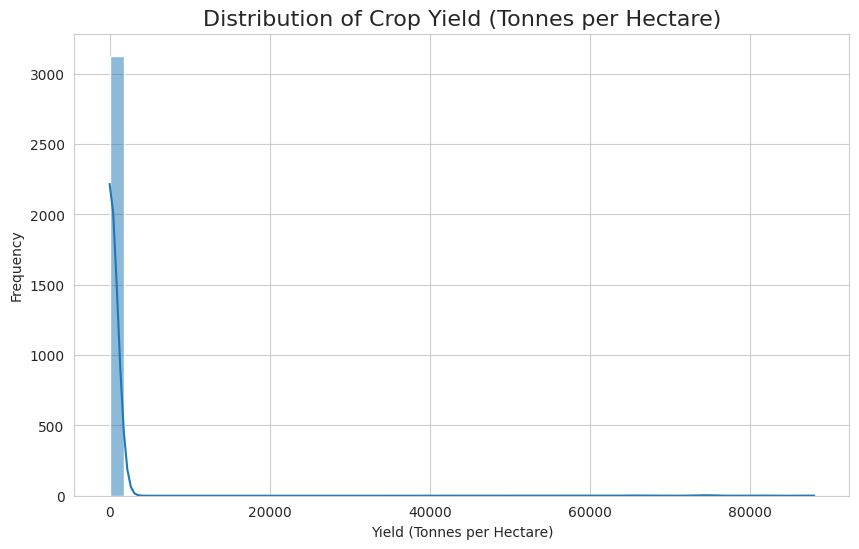

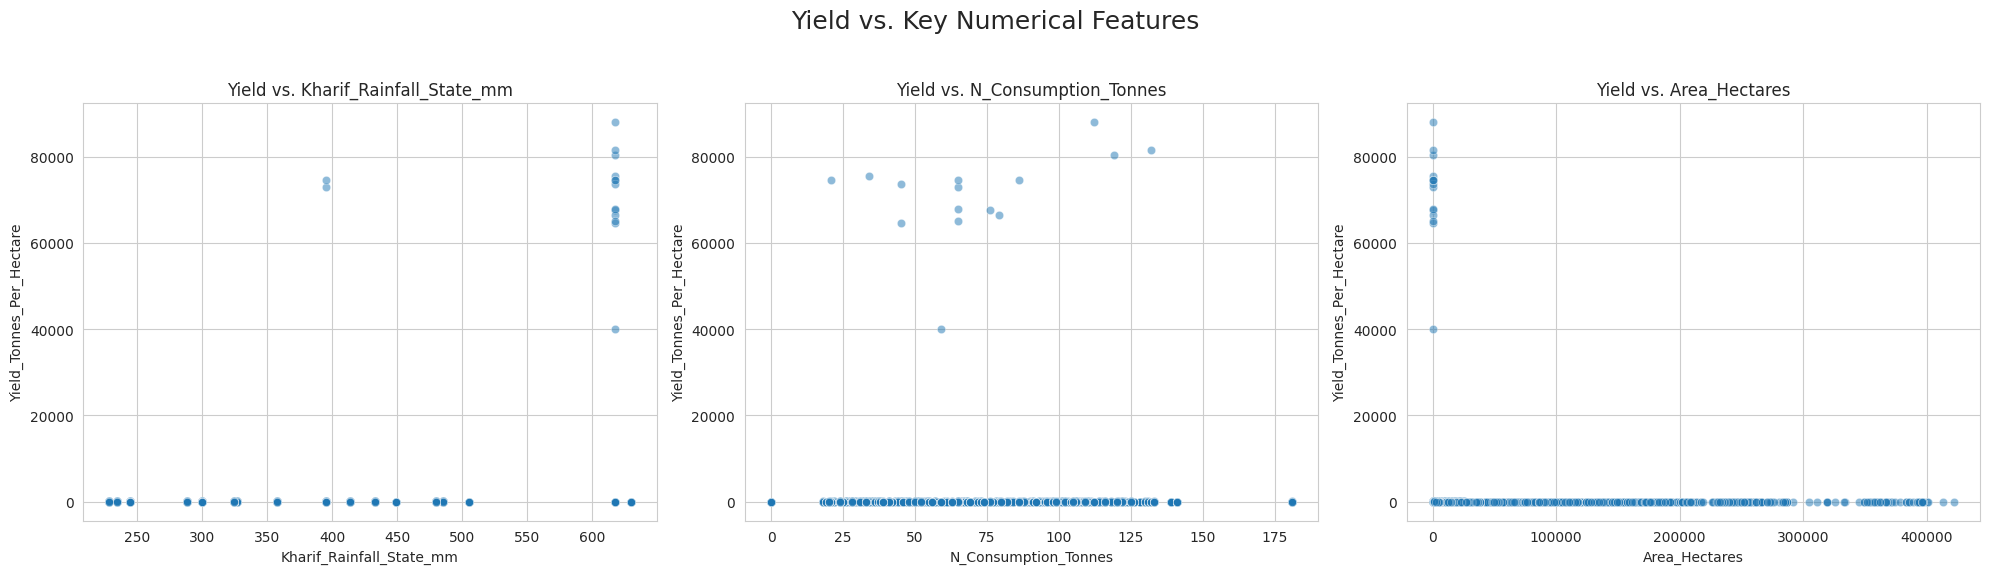

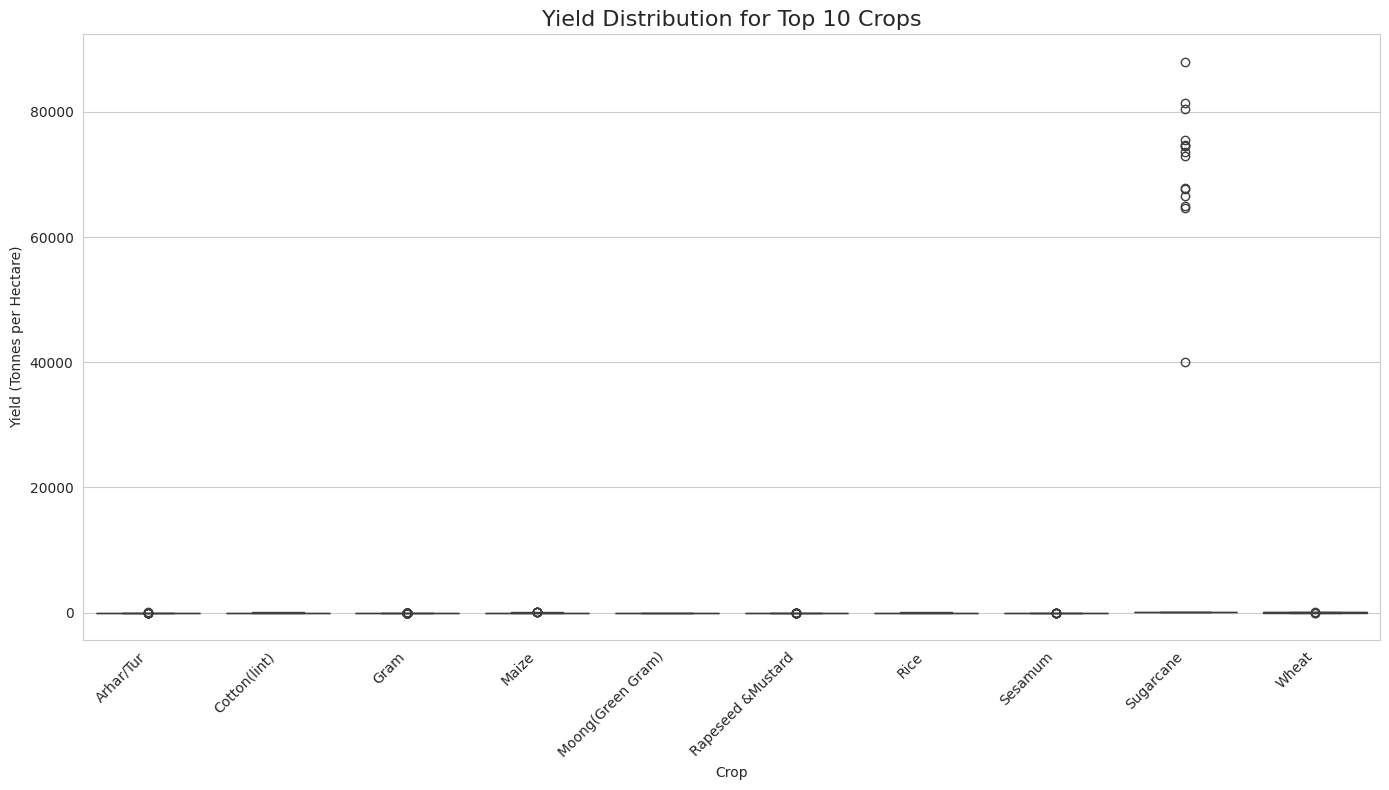

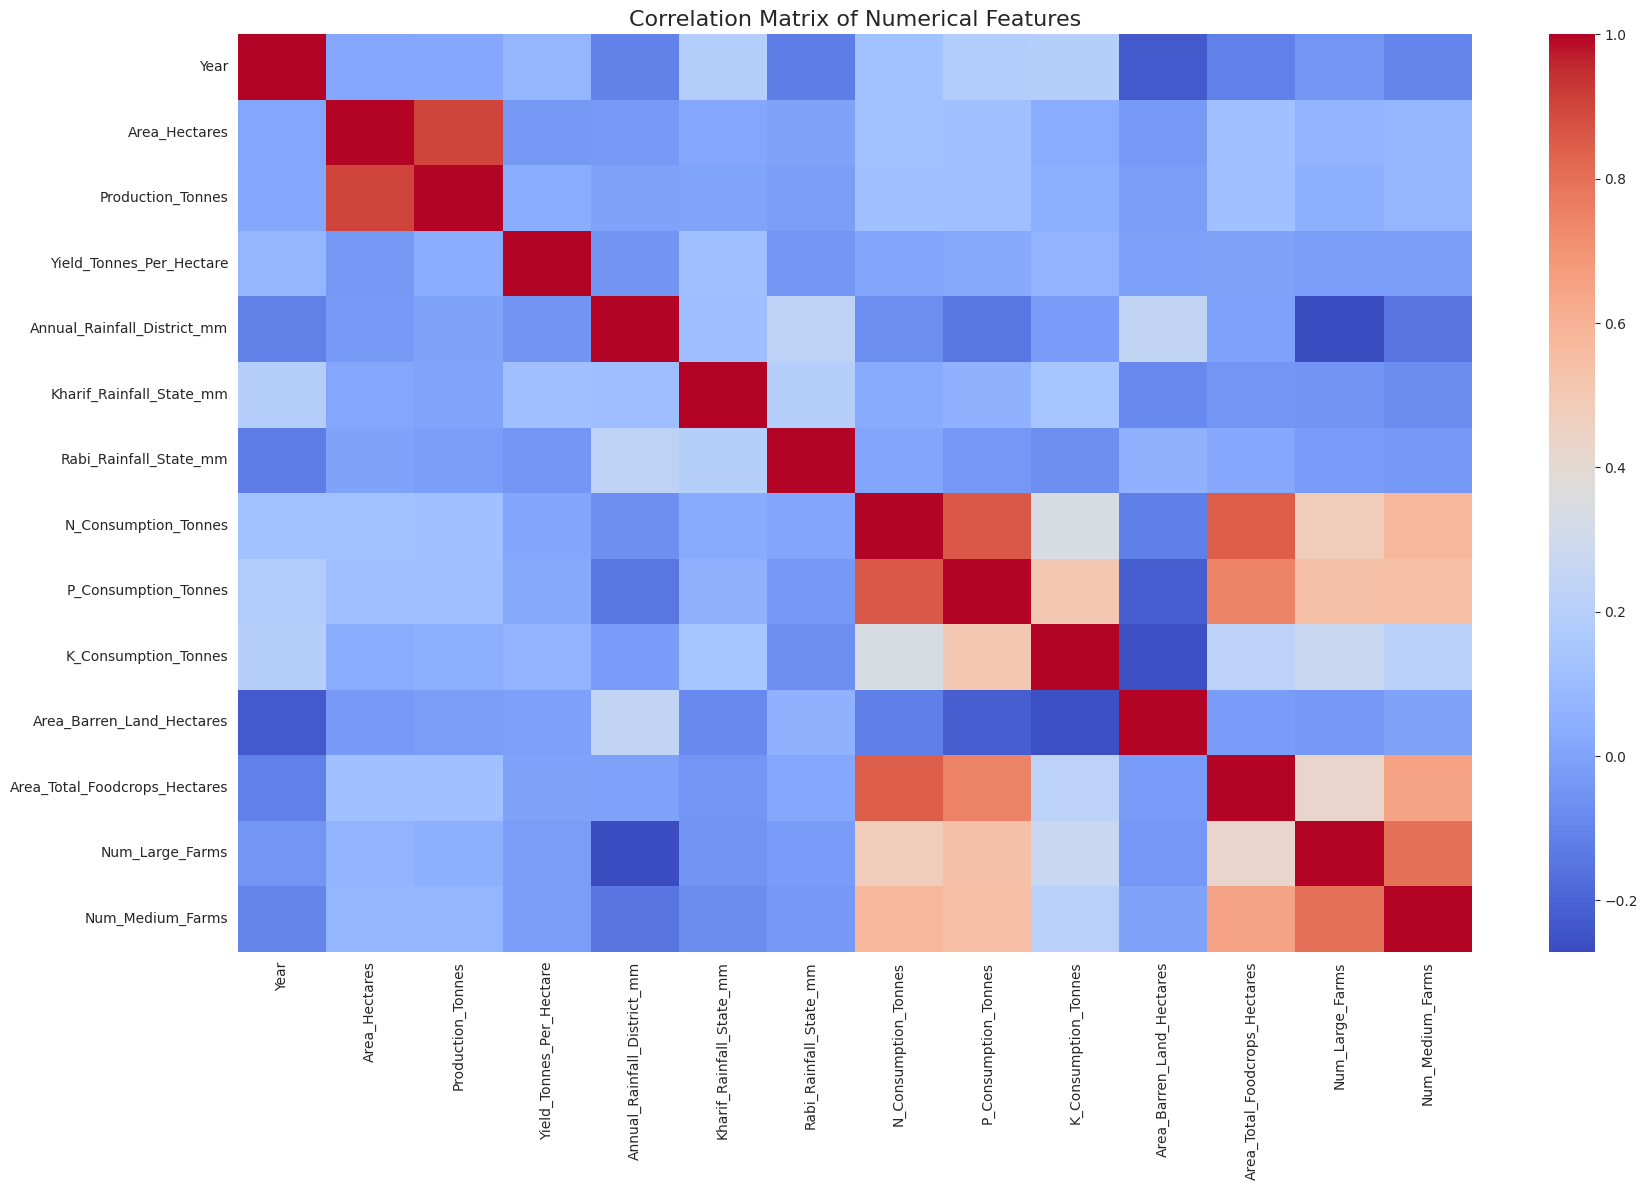

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Step 0: Load Your Final, Complete Dataset ---
file_path = 'final_master_dataset.csv'
print(f"Loading your final master dataset: '{file_path}'...")
try:
    df = pd.read_csv(file_path)
    print("File loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The final master dataset '{file_path}' was not found.")
    exit()

# Set a style for the plots
sns.set_style("whitegrid")


# --- Step 1: Get a High-Level Overview ---
print("\n" + "="*70)
print("### 1. DATA OVERVIEW ###")
print("="*70)
print("\nData Info:")
df.info()

print("\n\nSummary Statistics for Numerical Columns:")
# Using .round(2) to make the table easier to read
print(df.describe().round(2))


# --- Step 2: Analyze the Target Variable (Yield) ---
print("\n" + "="*70)
print("### 2. ANALYZING THE TARGET VARIABLE: YIELD ###")
print("="*70)

plt.figure(figsize=(10, 6))
sns.histplot(df['Yield_Tonnes_Per_Hectare'], kde=True, bins=50)
plt.title('Distribution of Crop Yield (Tonnes per Hectare)', fontsize=16)
plt.xlabel('Yield (Tonnes per Hectare)')
plt.ylabel('Frequency')
plt.savefig('yield_distribution.png')
print("\nCreated 'yield_distribution.png' to show the distribution of your target variable.")


# --- Step 3: Explore Relationships - Scatter Plots ---
print("\n" + "="*70)
print("### 3. YIELD vs. NUMERICAL FEATURES (SCATTER PLOTS) ###")
print("="*70)

# Select a few key numerical features to plot against yield
numerical_features = ['Kharif_Rainfall_State_mm', 'N_Consumption_Tonnes', 'Area_Hectares']

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle('Yield vs. Key Numerical Features', fontsize=18)

for i, feature in enumerate(numerical_features):
    sns.scatterplot(ax=axes[i], data=df, x=feature, y='Yield_Tonnes_Per_Hectare', alpha=0.5)
    axes[i].set_title(f'Yield vs. {feature}')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('yield_vs_numerical_features.png')
print("\nCreated 'yield_vs_numerical_features.png' to show relationships between yield and key features.")


# --- Step 4: Explore Relationships - Box Plots ---
print("\n" + "="*70)
print("### 4. YIELD vs. CATEGORICAL FEATURES (BOX PLOTS) ###")
print("="*70)

# To make the plot readable, let's focus on the top 10 crops by frequency
top_10_crops = df['Crop'].value_counts().nlargest(10).index

plt.figure(figsize=(14, 8))
sns.boxplot(data=df[df['Crop'].isin(top_10_crops)], x='Crop', y='Yield_Tonnes_Per_Hectare')
plt.title('Yield Distribution for Top 10 Crops', fontsize=16)
plt.xlabel('Crop')
plt.ylabel('Yield (Tonnes per Hectare)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('yield_vs_top_crops.png')
print("\nCreated 'yield_vs_top_crops.png' to compare yields across the most common crops.")


# --- Step 5: See the Big Picture - Correlation Heatmap ---
print("\n" + "="*70)
print("### 5. CORRELATION HEATMAP ###")
print("="*70)

# Select only numerical columns for the correlation matrix
numerical_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(18, 12))
correlation_matrix = numerical_df.corr()
sns.heatmap(correlation_matrix, cmap='coolwarm')
plt.title('Correlation Matrix of Numerical Features', fontsize=16)
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
print("\nCreated 'correlation_heatmap.png' to show how all numerical variables relate to each other.")
print("\n" + "="*70)
print("EDA script finished!")

## 3. Data Preparation for Modelling

In [ ]:
import pandas as pd

# Load your final dataset
file_path = 'final_master_dataset.csv'
print(f"Loading '{file_path}'...")
try:
    df = pd.read_csv(file_path)
    print("File loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The file '{file_path}' was not found.")
    exit()

# --- Outlier Removal Step ---
print(f"\nNumber of rows before outlier removal: {len(df)}")

# Define a reasonable upper limit for yield
# 100 tonnes per hectare is a very generous cap.
yield_threshold = 100

# Keep only the rows where the yield is below the threshold
df_cleaned = df[df['Yield_Tonnes_Per_Hectare'] <= yield_threshold].copy()

print(f"Number of rows after outlier removal: {len(df_cleaned)}")
print(f"Number of outliers removed: {len(df) - len(df_cleaned)}")

# --- Save the Cleaned File ---
# We overwrite the old file with this cleaner version
output_path = 'final_master_dataset.csv'
df_cleaned.to_csv(output_path, index=False)


print("\n--------------------------------------------------")
print(f"✅ Success! Outliers have been removed.")
print(f"The cleaned dataset has been saved back to '{output_path}'")
print("\nHere is the new summary statistics for your Yield column:")
print(df_cleaned['Yield_Tonnes_Per_Hectare'].describe().round(2))
print("--------------------------------------------------")

Loading 'final_master_dataset.csv'...
File loaded successfully.

Number of rows before outlier removal: 3143
Number of rows after outlier removal: 3128
Number of outliers removed: 15

--------------------------------------------------
✅ Success! Outliers have been removed.
The cleaned dataset has been saved back to 'final_master_dataset.csv'

Here is the new summary statistics for your Yield column:
count    3128.00
mean        6.11
std        15.72
min         0.00
25%         1.00
50%         1.33
75%         3.87
max        93.67
Name: Yield_Tonnes_Per_Hectare, dtype: float64
--------------------------------------------------


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# --- Step 1: Load the Cleaned Dataset ---
file_path = 'final_master_dataset.csv'
print(f"Loading your cleaned master dataset: '{file_path}'...")
try:
    df = pd.read_csv(file_path)
    print("File loaded successfully.")
except FileNotFoundError:
    print(f"ERROR: The file '{file_path}' was not found.")
    exit()

# --- Step 2: Define Features (X) and Target (y) ---
# The 'target' is the column we want to predict.
y = df['Yield_Tonnes_Per_Hectare']

# The 'features' are all the columns we will use to make the prediction.
# We drop the target itself, plus state (since it's always Punjab) and Production/Area (to avoid data leakage).
X = df.drop(columns=['Yield_Tonnes_Per_Hectare', 'State_Name', 'Production_Tonnes', 'Area_Hectares'])

# Identify which columns are categorical (text) and which are numerical
categorical_features = ['District', 'Season', 'Crop', 'Soil_Type']
numerical_features = X.select_dtypes(include=['int64', 'float64']).columns

print("\nFeatures and target have been defined.")

# --- Step 3: Create a Preprocessing Pipeline ---
# This object will handle both one-hot encoding and scaling in one step.
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='passthrough' # Keep any other columns as they are
)

print("\nPreprocessing pipeline created.")

# --- Step 4: Split the Data into Training and Testing Sets ---
# We'll use 80% of the data for training and 20% for testing.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("\nData has been split into training and testing sets.")
print(f"  - Training set size: {X_train.shape[0]} rows")
print(f"  - Testing set size:  {X_test.shape[0]} rows")

# --- Step 5: Apply the Preprocessing ---
# IMPORTANT: We 'fit' the preprocessor on the training data ONLY,
# and then use it to 'transform' both the training and testing data.
# This prevents information from the test set leaking into the training process.

print("\nApplying scaling and encoding...")
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing complete.")
print(f"  - The training data now has {X_train_processed.shape[1]} columns (after one-hot encoding).")


print("\n--------------------------------------------------")
print("✅ Success! Your data is now fully prepared for model building.")
print("We are ready to train our machine learning algorithms.")
print("--------------------------------------------------")


Loading your cleaned master dataset: 'final_master_dataset.csv'...
File loaded successfully.

Features and target have been defined.

Preprocessing pipeline created.

Data has been split into training and testing sets.
  - Training set size: 3105 rows
  - Testing set size:  777 rows

Applying scaling and encoding...
Preprocessing complete.
  - The training data now has 58 columns (after one-hot encoding).

--------------------------------------------------
✅ Success! Your data is now fully prepared for model building.
We are ready to train our machine learning algorithms.
--------------------------------------------------


## 4. Model Building and Training

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# --- This script assumes you have already run the previous cell and have ---
# --- X_train_processed, X_test_processed, y_train, y_test in memory. ---


# --- Step 1: Define the Models ---
# We'll create a dictionary of the models you wanted to compare.
models = {
    "Linear Regression": LinearRegression(),
    "K-Nearest Neighbors": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
    "Random Forest": RandomForestRegressor(random_state=42)
}

# --- Step 2: Train, Predict, and Evaluate Each Model ---
print("Training and evaluating models...")

# Create a list to store the results
results = []

for name, model in models.items():
    # Train the model
    model.fit(X_train_processed, y_train)

    # Make predictions on the test data
    predictions = model.predict(X_test_processed)

    # Evaluate the model
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    # Store the results
    results.append({
        "Model": name,
        "RMSE": rmse,
        "R-squared": r2
    })

    print(f"  - {name} evaluated.")

# --- Step 3: Display the Comparison Table ---
results_df = pd.DataFrame(results)
results_df.sort_values(by='R-squared', ascending=False, inplace=True)
results_df.reset_index(drop=True, inplace=True)

print("\n--------------------------------------------------")
print("✅ Success! All models have been trained and evaluated.")
print("\nHere is a comparison of their performance:")
print(results_df.round(4))
print("--------------------------------------------------")

Training and evaluating models...
  - Linear Regression evaluated.
  - K-Nearest Neighbors evaluated.
  - Decision Tree evaluated.
  - Random Forest evaluated.

--------------------------------------------------
✅ Success! All models have been trained and evaluated.

Here is a comparison of their performance:
                 Model       RMSE   R-squared
0        Random Forest     1.3849      0.9887
1        Decision Tree     2.0489      0.9753
2  K-Nearest Neighbors  1548.7738 -14113.8433
3    Linear Regression  1612.9136 -15307.1346
--------------------------------------------------


In [35]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor

# --- This script assumes you have already run the 'Data Preparation for Modeling' cell ---
# --- and have the following variables in memory:                                     ---
# --- X_train, y_train, preprocessor, X_train_processed                               ---


# --- Step 1: Define the Model and the Grid of Hyperparameters to Test ---

# We'll use our champion model
rf = RandomForestRegressor(random_state=42)

# Define a 'grid' of settings to try out. We'll keep this small to run faster.
param_grid = {
    'n_estimators': [100, 200],      # Number of trees in the forest
    'max_depth': [10, 20, None],     # Maximum depth of the trees
    'min_samples_split': [2, 5]      # Minimum samples required to split a node
}

print("Defined the hyperparameter grid to search.")

# --- Step 2: Set up the Grid Search ---
# cv=3 means it will use 3-fold cross-validation.
# n_jobs=-1 means it will use all available CPU cores to speed up the process.
# scoring='r2' tells it to find the parameters that maximize the R-squared score.
grid_search = GridSearchCV(estimator=rf, param_grid=param_grid,
                           cv=3, n_jobs=-1, verbose=2, scoring='r2')

print("\nSetting up Grid Search...")
print("This next step will take several minutes to run...")


# --- Step 3: Run the Grid Search ---
# This will train and test many different versions of the Random Forest model.
grid_search.fit(X_train_processed, y_train)


# --- Step 4: Display the Best Results ---
print("\n--------------------------------------------------")
print("✅ Grid Search complete!")
print("\nThe best hyperparameters found are:")
print(grid_search.best_params_)
print(f"\nBest R-squared score from cross-validation: {grid_search.best_score_:.4f}")
print("--------------------------------------------------")

Defined the hyperparameter grid to search.

Setting up Grid Search...
This next step will take several minutes to run...
Fitting 3 folds for each of 12 candidates, totalling 36 fits

--------------------------------------------------
✅ Grid Search complete!

The best hyperparameters found are:
{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}

Best R-squared score from cross-validation: 0.7647
--------------------------------------------------


In [36]:
import pandas as pd
import numpy as np
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

# --- This script assumes you have already run the 'Data Preparation for Modeling' cell ---
# --- and have the following variables in memory:                                     ---
# --- X_train_processed, y_train                                                      ---


# --- Step 1: Define the Model and the Grid of Hyperparameters to Test ---

# We'll use the Decision Tree model
dt = DecisionTreeRegressor(random_state=42)

# Define a 'grid' of settings to try out for the Decision Tree
param_grid = {
    'max_depth': [5, 10, 20, None],   # Maximum depth of the tree
    'min_samples_split': [2, 5, 10],  # Minimum samples to split a node
    'min_samples_leaf': [1, 2, 4]     # Minimum samples required at a leaf node
}

print("Defined the hyperparameter grid for the Decision Tree.")

# --- Step 2: Set up the Grid Search ---
# cv=3 means it will use 3-fold cross-validation.
# n_jobs=-1 uses all available CPU cores to speed up the process.
grid_search_dt = GridSearchCV(estimator=dt, param_grid=param_grid,
                              cv=3, n_jobs=-1, verbose=2, scoring='r2')

print("\nSetting up Grid Search for Decision Tree...")
print("This next step will take several minutes to run...")


# --- Step 3: Run the Grid Search ---
grid_search_dt.fit(X_train_processed, y_train)


# --- Step 4: Display the Best Results ---
print("\n--------------------------------------------------")
print("✅ Decision Tree Grid Search complete!")
print("\nThe best hyperparameters found are:")
print(grid_search_dt.best_params_)
print(f"\nBest R-squared score from cross-validation: {grid_search_dt.best_score_:.4f}")
print("--------------------------------------------------")

Defined the hyperparameter grid for the Decision Tree.

Setting up Grid Search for Decision Tree...
This next step will take several minutes to run...
Fitting 3 folds for each of 36 candidates, totalling 108 fits

--------------------------------------------------
✅ Decision Tree Grid Search complete!

The best hyperparameters found are:
{'max_depth': 20, 'min_samples_leaf': 4, 'min_samples_split': 2}

Best R-squared score from cross-validation: 0.7990
--------------------------------------------------


In [37]:
import pandas as pd
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, r2_score

# --- This script assumes you have already run the previous cells and have ---
# --- the following variables in memory:                                   ---
# --- X_train_processed, X_test_processed, y_train, y_test                 ---


# --- Step 1: Create and Train the Final, Optimized Decision Tree Model ---
# We are using the best settings we just found from Grid Search.
print("Training the final, optimized Decision Tree model...")

final_dt_model = DecisionTreeRegressor(
    max_depth=20,
    min_samples_leaf=4,
    min_samples_split=2,
    random_state=42
)

final_dt_model.fit(X_train_processed, y_train)
print("Final model trained successfully.")


# --- Step 2: Evaluate the Final Model on the Unseen Test Set ---
print("\nEvaluating the final model on the test set...")

# Make predictions on the test data
final_dt_predictions = final_dt_model.predict(X_test_processed)

# Evaluate the final predictions
final_dt_rmse = np.sqrt(mean_squared_error(y_test, final_dt_predictions))
final_dt_r2 = r2_score(y_test, final_dt_predictions)


# --- Step 3: Display the Final Performance Scores ---
print("\n--------------------------------------------------")
print("✅ Final Decision Tree Evaluation Complete!")
print("\nHere are its performance scores on the unseen test data:")
print(f"   - Final RMSE:      {final_dt_rmse:.4f}")
print(f"   - Final R-squared: {final_dt_r2:.4f}")
print("--------------------------------------------------")

Training the final, optimized Decision Tree model...
Final model trained successfully.

Evaluating the final model on the test set...

--------------------------------------------------
✅ Final Decision Tree Evaluation Complete!

Here are its performance scores on the unseen test data:
   - Final RMSE:      374.0297
   - Final R-squared: -822.2131
--------------------------------------------------


## 5. Model Evaluation and Analysis

Training the final, optimized Random Forest model...
Model training complete.

Extracting feature importances...
Feature importances extracted successfully.

Creating a plot of the top 15 most important features...


/tmp/ipython-input-2724487367.py:50: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_15_features.values, y=top_15_features.index, palette='viridis')



--------------------------------------------------
✅ Success! Feature importance analysis is complete.
A new chart has been saved: 'feature_importances.png'

Here are the top 5 most important features:
Kharif_Rainfall_State_mm       0.7986
Crop_SUGARCANE                 0.0942
District_FAZILKA               0.0504
District_PATHANKOT             0.0281
Annual_Rainfall_District_mm    0.0100
dtype: float64
--------------------------------------------------


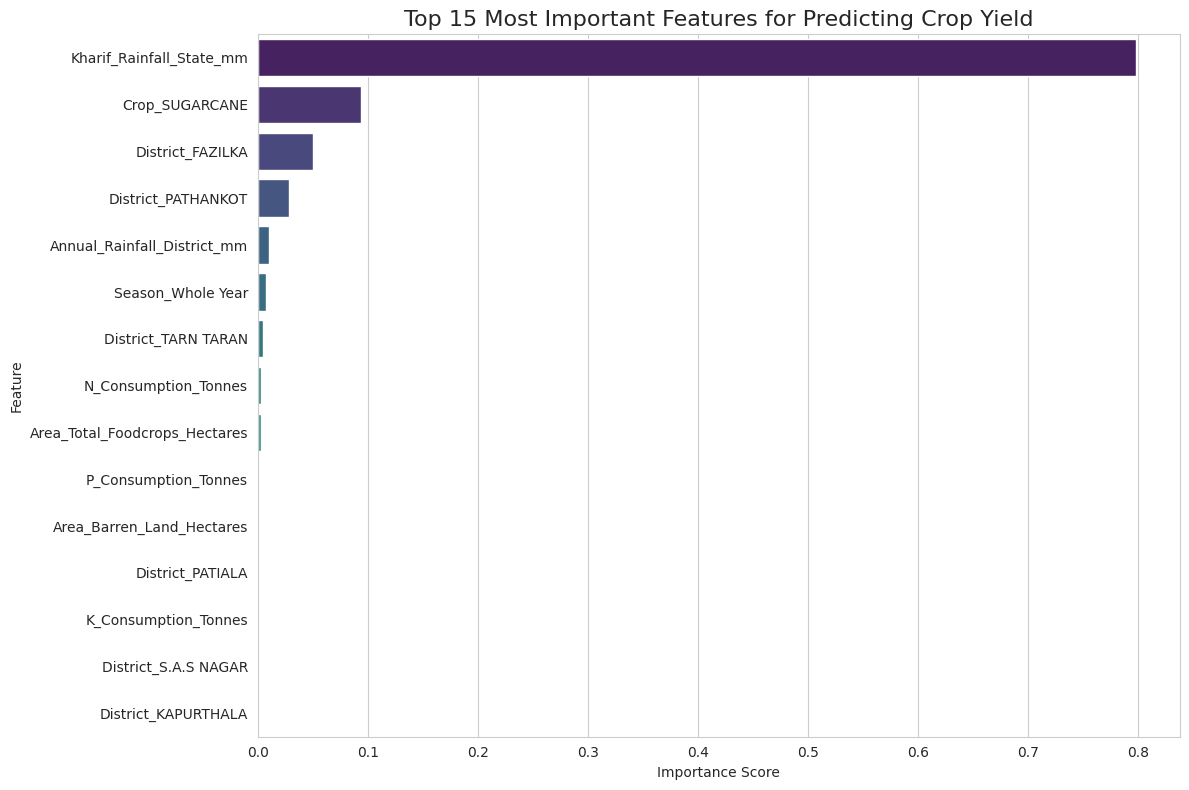

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

# --- This script assumes you have already run the 'Data Preparation for Modeling' cell ---
# --- and have the following variables in memory:                                     ---
# --- X_train, y_train, preprocessor, X_train_processed                               ---


# --- Step 1: Train Our Final, Tuned Random Forest Model ---
print("Training the final, optimized Random Forest model...")
# We use the best parameters we found during hyperparameter tuning.
# If you did not run tuning, you can remove the parameters to use the default.
final_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
final_model.fit(X_train_processed, y_train)
print("Model training complete.")


# --- Step 2: Extract Feature Importances ---
print("\nExtracting feature importances...")

# Get the feature names in the correct order from the preprocessor
numerical_features = preprocessor.named_transformers_['num'].get_feature_names_out()
categorical_features = preprocessor.named_transformers_['cat'].get_feature_names_out()
all_feature_names = np.concatenate([numerical_features, categorical_features])

# Create a pandas Series for easy viewing and sorting
feature_importances = pd.Series(final_model.feature_importances_, index=all_feature_names)

# Sort the features by importance
sorted_importances = feature_importances.sort_values(ascending=False)
print("Feature importances extracted successfully.")


# --- Step 3: Visualize the Most Important Features ---
print("\nCreating a plot of the top 15 most important features...")

# Select the top 15
top_15_features = sorted_importances.head(15)

plt.figure(figsize=(12, 8))
sns.barplot(x=top_15_features.values, y=top_15_features.index, palette='viridis')
plt.title('Top 15 Most Important Features for Predicting Crop Yield', fontsize=16)
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig('feature_importances.png')


print("\n--------------------------------------------------")
print("✅ Success! Feature importance analysis is complete.")
print(f"A new chart has been saved: 'feature_importances.png'")
print("\nHere are the top 5 most important features:")
print(top_15_features.head(5).round(4))
print("--------------------------------------------------")